In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
df = pd.read_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\retail_clean.xlsx"
)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [8]:
df[["Invoice", "StockCode", "Quantity", "Price", "InvoiceDate"]].head()

,Invoice,StockCode,Quantity,Price,InvoiceDate
0,536365,85123A,6,2.55,2010-12-01 08:26:00
1,536365,71053,6,3.39,2010-12-01 08:26:00
2,536365,84406B,8,2.75,2010-12-01 08:26:00
3,536365,84029G,6,3.39,2010-12-01 08:26:00
4,536365,84029E,6,3.39,2010-12-01 08:26:00


In [9]:
print("Date range:")
print(df["InvoiceDate"].min())
print(df["InvoiceDate"].max())

Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


In [10]:
# For our initial demand analysis, we'll focus on records with positive quantity and positive price

sales = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

In [11]:
print("Original rows:", len(df))
print("Selected sales rows:", len(sales))

Original rows: 536642
Selected sales rows: 524879


Daily Demand

In [12]:
daily_demand = (
    sales
    .set_index("InvoiceDate")
    .resample("D")["Quantity"]
    .sum()
    .reset_index()
)

In [13]:
daily_demand.columns = ["Date", "Demand"]

In [14]:
daily_demand.head(10)

,Date,Demand
0,2010-12-01,26818
1,2010-12-02,31264
2,2010-12-03,16158
3,2010-12-04,0
4,2010-12-05,16242
5,2010-12-06,21619
6,2010-12-07,25180
7,2010-12-08,23041
8,2010-12-09,19898
9,2010-12-10,20973


In [15]:
daily_demand.tail(10)

,Date,Demand
364,2011-11-30,28356
365,2011-12-01,27004
366,2011-12-02,28690
367,2011-12-03,0
368,2011-12-04,12296
369,2011-12-05,44497
370,2011-12-06,30377
371,2011-12-07,41789
372,2011-12-08,35010
373,2011-12-09,93950


In [16]:
print("Total days:", len(daily_demand))
print("Days with zero demand:", (daily_demand["Demand"] == 0).sum())
print("Missing demand values:", daily_demand["Demand"].isna().sum())

Total days: 374
Days with zero demand: 69
Missing demand values: 0


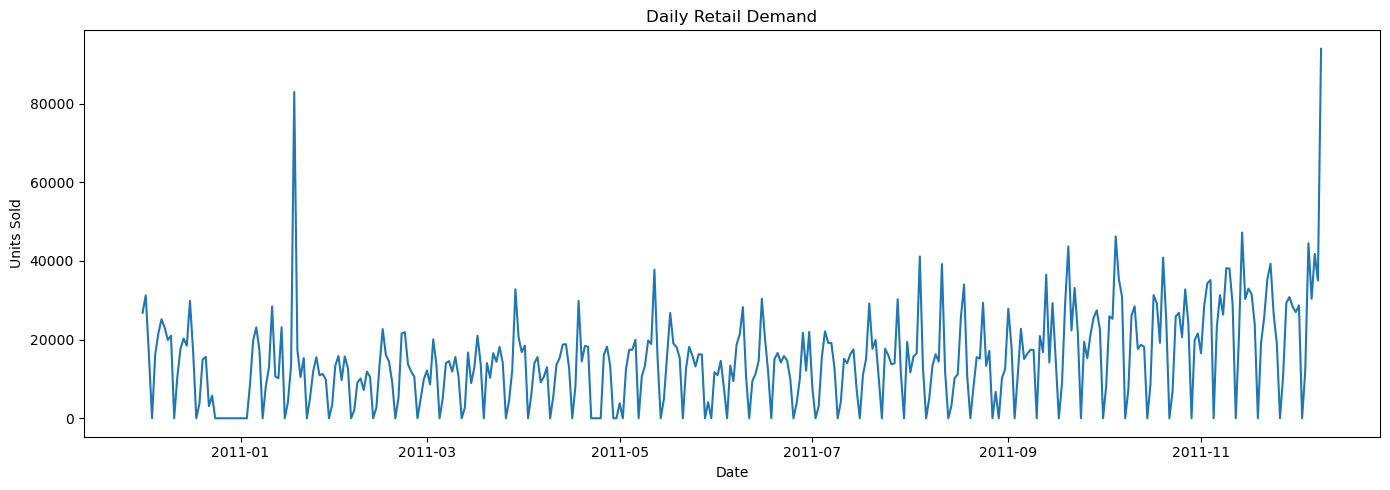

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand["Date"],
    daily_demand["Demand"]
)

plt.title("Daily Retail Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

Monthly Demand

In [18]:
monthly_demand = (
    daily_demand
    .set_index("Date")["Demand"]
    .resample("MS")
    .sum()
)

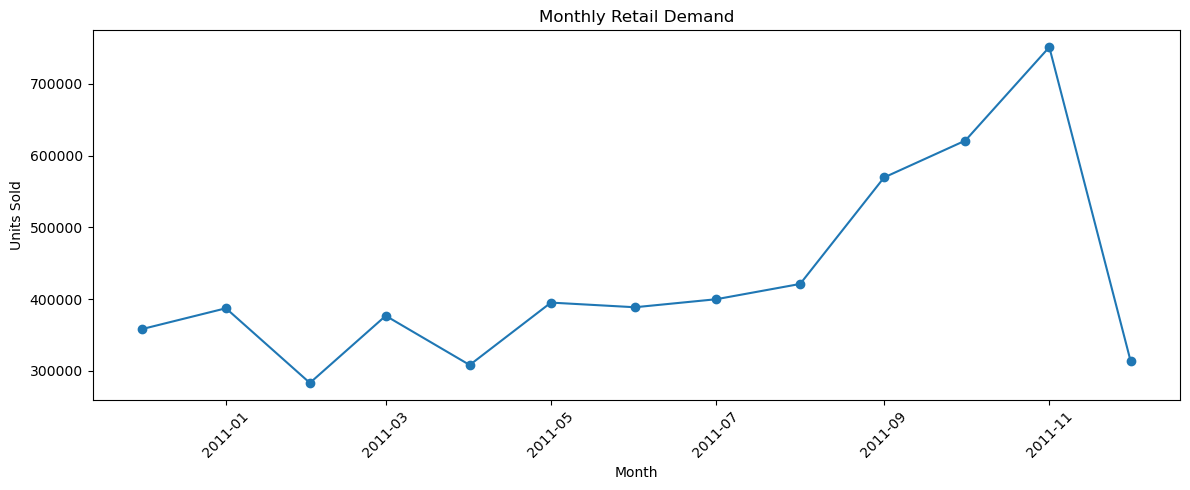

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_demand.index,
    monthly_demand.values,
    marker="o"
)

plt.title("Monthly Retail Demand")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
'''
Splitting the data into training and testing sets based on date 
cause in forecasting, we must train on the past and test on the future. 
A random split could let future information leak into training.
'''

split_idx = int(len(daily_demand) * 0.8)

train = daily_demand.iloc[:split_idx].copy()
test = daily_demand.iloc[split_idx:].copy()

print("Training period:", train["Date"].min(), "to", train["Date"].max())
print("Testing period:", test["Date"].min(), "to", test["Date"].max())

print("Training rows:", len(train))
print("Testing rows:", len(test))

Training period: 2010-12-01 00:00:00 to 2011-09-25 00:00:00
Testing period: 2011-09-26 00:00:00 to 2011-12-09 00:00:00
Training rows: 299
Testing rows: 75


In [21]:
# Baseline model / forecast

baseline_value = train["Demand"].iloc[-1]

test["Baseline_Prediction"] = baseline_value

print("Baseline daily prediction:", baseline_value)
test[["Date", "Demand", "Baseline_Prediction"]].head(10)

Baseline daily prediction: 19424


,Date,Demand,Baseline_Prediction
299,2011-09-26,15249,19424
300,2011-09-27,21231,19424
301,2011-09-28,25530,19424
302,2011-09-29,27456,19424
303,2011-09-30,22553,19424
304,2011-10-01,0,19424
305,2011-10-02,8332,19424
306,2011-10-03,25942,19424
307,2011-10-04,25284,19424
308,2011-10-05,46222,19424


In [22]:
# Measuring forecast accuracy using Mean Absolute Error (MAE)

mae = np.mean(
    np.abs(test["Demand"] - test["Baseline_Prediction"])
)

print("Baseline MAE:", round(mae, 2))

Baseline MAE: 11703.49


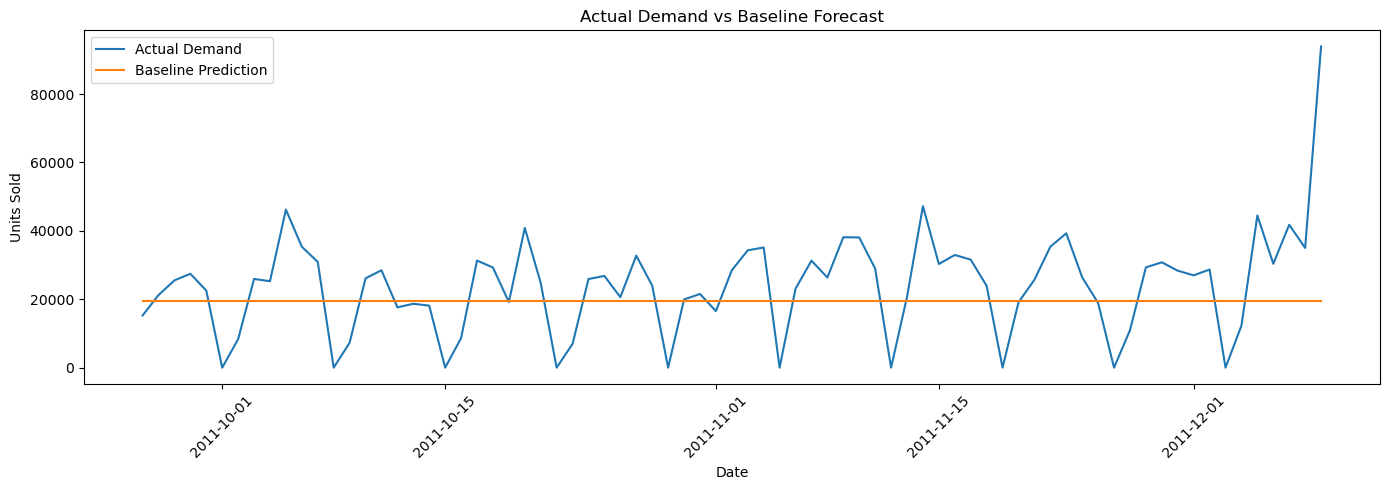

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    test["Date"],
    test["Demand"],
    label="Actual Demand"
)

plt.plot(
    test["Date"],
    test["Baseline_Prediction"],
    label="Baseline Prediction"
)

plt.title("Actual Demand vs Baseline Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
# Use the last 7 days of training data as the weekly pattern
last_week = train["Demand"].tail(7).to_numpy()

# Repeat that weekly pattern across the testing period
test["Weekly_Baseline"] = np.resize(
    last_week,
    len(test)
)

test[["Date", "Demand", "Baseline_Prediction", "Weekly_Baseline"]].head(14)

,Date,Demand,Baseline_Prediction,Weekly_Baseline
299,2011-09-26,15249,19424,29248
300,2011-09-27,21231,19424,43683
301,2011-09-28,25530,19424,22312
302,2011-09-29,27456,19424,33144
303,2011-09-30,22553,19424,21872
304,2011-10-01,0,19424,0
305,2011-10-02,8332,19424,19424
306,2011-10-03,25942,19424,29248
307,2011-10-04,25284,19424,43683
308,2011-10-05,46222,19424,22312


In [25]:
baseline_mae = np.mean(
    np.abs(test["Demand"] - test["Baseline_Prediction"])
)

weekly_mae = np.mean(
    np.abs(test["Demand"] - test["Weekly_Baseline"])
)

print("Simple Baseline MAE:", round(baseline_mae, 2))
print("Weekly Baseline MAE:", round(weekly_mae, 2))

Simple Baseline MAE: 11703.49
Weekly Baseline MAE: 8097.8


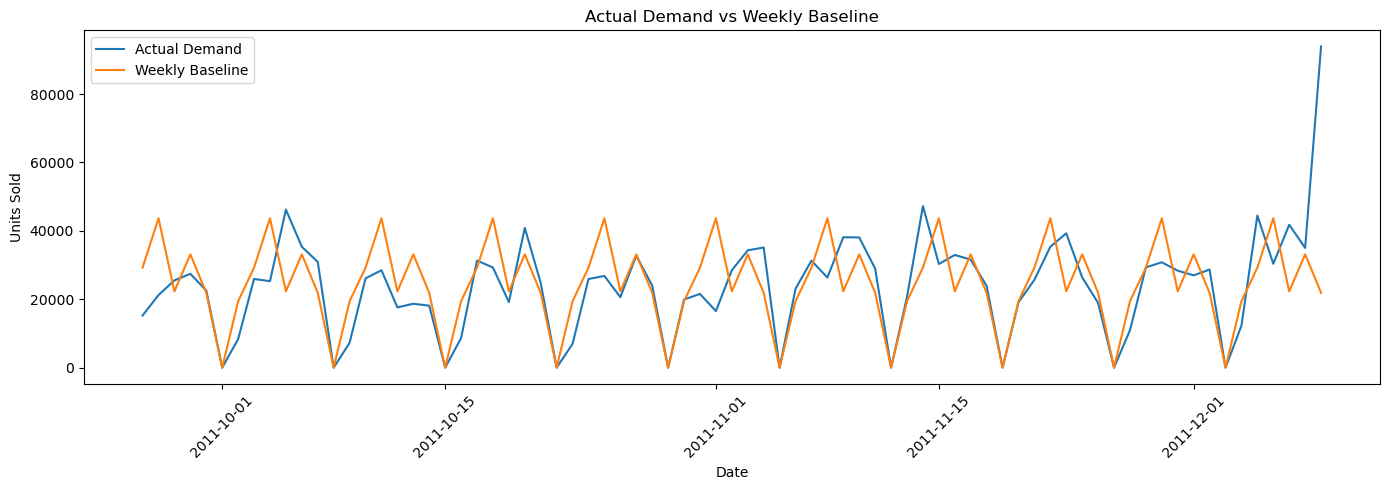

In [26]:
plt.figure(figsize=(14, 5))

plt.plot(
    test["Date"],
    test["Demand"],
    label="Actual Demand"
)

plt.plot(
    test["Date"],
    test["Weekly_Baseline"],
    label="Weekly Baseline"
)

plt.title("Actual Demand vs Weekly Baseline")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
def evaluate_forecast(actual, predicted, model_name):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    return {
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    }

In [28]:
baseline_results = [
    evaluate_forecast(
        test["Demand"],
        test["Baseline_Prediction"],
        "Simple Baseline"
    ),
    evaluate_forecast(
        test["Demand"],
        test["Weekly_Baseline"],
        "Weekly Baseline"
    )
]

baseline_results_df = pd.DataFrame(baseline_results)
baseline_results_df

,Model,MAE,RMSE
0,Simple Baseline,11703.49,15467.27
1,Weekly Baseline,8097.80,12894.79


In [ ]:
# Preparing data for Prophet model

from prophet import Prophet
prophet_df = daily_demand.rename(
    columns={
        "Date": "ds",
        "Demand": "y"
    }
).copy()

prophet_df.head()

,ds,y
0,2010-12-01,26818
1,2010-12-02,31264
2,2010-12-03,16158
3,2010-12-04,0
4,2010-12-05,16242


In [ ]:
# Splitting the data into training and testing sets for Prophet model

prophet_train = prophet_df.iloc[:split_idx].copy()
prophet_test = prophet_df.iloc[split_idx:].copy()

print("Training rows:", len(prophet_train))
print("Testing rows:", len(prophet_test))

Training rows: 299
Testing rows: 75


In [33]:
model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=False,
    daily_seasonality=False
)

model.fit(prophet_train)

22:47:53 - cmdstanpy - INFO - Chain [1] start processing
22:47:53 - cmdstanpy - INFO - Chain [1] done processing


In [34]:
forecast = model.predict(prophet_test[["ds"]])

prophet_test["Prophet_Prediction"] = forecast["yhat"].to_numpy()

prophet_test[
    ["ds", "y", "Prophet_Prediction"]
].head(10)

,ds,y,Prophet_Prediction
299,2011-09-26,15249,16453.276636
300,2011-09-27,21231,22784.133202
301,2011-09-28,25530,19464.933708
302,2011-09-29,27456,23503.447856
303,2011-09-30,22553,16083.735962
304,2011-10-01,0,3533.077524
305,2011-10-02,8332,11182.294485
306,2011-10-03,25942,16666.914127
307,2011-10-04,25284,22997.770693
308,2011-10-05,46222,19678.571199


In [35]:
# Accuracy evaluation for Prophet model
prophet_mae = np.mean(
    np.abs(
        prophet_test["y"] -
        prophet_test["Prophet_Prediction"]
    )
)

prophet_rmse = np.sqrt(
    np.mean(
        (
            prophet_test["y"] -
            prophet_test["Prophet_Prediction"]
        ) ** 2
    )
)

print("Prophet MAE:", round(prophet_mae, 2))
print("Prophet RMSE:", round(prophet_rmse, 2))

Prophet MAE: 8716.01
Prophet RMSE: 13151.06


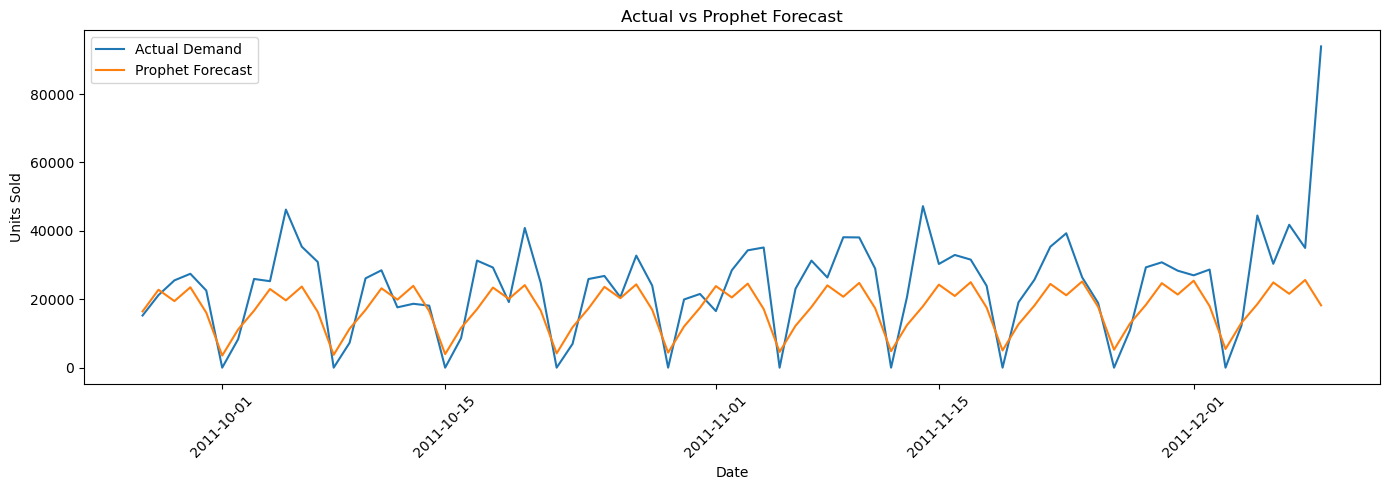

In [37]:
plt.figure(figsize=(14, 5))

plt.plot(
    prophet_test["ds"],
    prophet_test["y"],
    label="Actual Demand"
)

plt.plot(
    prophet_test["ds"],
    prophet_test["Prophet_Prediction"],
    label="Prophet Forecast"
)

plt.title("Actual vs Prophet Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
negative_predictions = (
    prophet_test["Prophet_Prediction"] < 0
).sum()

print("Negative forecast days:", negative_predictions)

Negative forecast days: 0


In [41]:
# Comparing all 3 models

all_results = baseline_results + [
    evaluate_forecast(
        prophet_test["y"],
        prophet_test["Prophet_Prediction"],
        "Prophet"
    )
]

results_df = pd.DataFrame(all_results)
results_df.sort_values("MAE")

,Model,MAE,RMSE
1,Weekly Baseline,8097.80,12894.79
2,Prophet,8716.01,13151.06
0,Simple Baseline,11703.49,15467.27


In [42]:
results_df = results_df.sort_values("MAE").reset_index(drop=True)

results_df.to_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\forecast_model_comparison.xlsx",
    index=False
)

results_df

,Model,MAE,RMSE
0,Weekly Baseline,8097.80,12894.79
1,Prophet,8716.01,13151.06
2,Simple Baseline,11703.49,15467.27


In [44]:
forecast_output = prophet_test[
    ["ds", "y", "Prophet_Prediction"]
].copy()

forecast_output = forecast_output.rename(
    columns={
        "ds": "Date",
        "y": "Actual_Demand"
    }
)

forecast_output.to_csv(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\prophet_forecast_results.csv",
    index=False
)

The weekly seasonal baseline outperformed Prophet on the chronological test period. The weekly baseline achieved an MAE of 8,097.80 and RMSE of 12,894.79, compared with Prophet's MAE of 8,716.01 and RMSE of 13,151.06. Therefore, the weekly baseline is the preferred model among those evaluated so far.